In [190]:
import math, os, pickle
import numpy as np
import matplotlib.pyplot as plt
import updraftClasses as up
import modelReadIn as modelread
import globalVariables as GV
import found2Dupdraft as f2D
from matplotlib import cm
import pandas as pd
from mpl_toolkits.mplot3d import Axes3D

In [191]:
global modelParams, TrackerParams, modelData

In [192]:
exp="lb_urb12"

In [193]:
print 'Loading updrafts...'

Loading updrafts...


Done reading in updrafts...
((23, 61), (23, 61))
/glade/u/home/fdemartin/SPOUT/tracks/yup_lb_urb12_0.csv
Done reading in updrafts...
((25, 61), (25, 61))
/glade/u/home/fdemartin/SPOUT/tracks/yup_lb_urb12_1.csv
Done reading in updrafts...
((22, 61), (22, 61))
/glade/u/home/fdemartin/SPOUT/tracks/yup_lb_urb12_2.csv
Done reading in updrafts...
((32, 61), (32, 61))
/glade/u/home/fdemartin/SPOUT/tracks/yup_lb_urb12_3.csv
Done reading in updrafts...
((23, 61), (23, 61))
/glade/u/home/fdemartin/SPOUT/tracks/yup_lb_urb12_4.csv
Done reading in updrafts...
((27, 61), (27, 61))
/glade/u/home/fdemartin/SPOUT/tracks/yup_lb_urb12_5.csv
Done reading in updrafts...
((22, 61), (22, 61))
/glade/u/home/fdemartin/SPOUT/tracks/yup_lb_urb12_6.csv
Done reading in updrafts...
((16, 61), (16, 61))
/glade/u/home/fdemartin/SPOUT/tracks/yup_lb_urb12_7.csv
Done reading in updrafts...
((21, 61), (21, 61))
/glade/u/home/fdemartin/SPOUT/tracks/yup_lb_urb12_8.csv
Done reading in updrafts...
((19, 61), (19, 61))
/glade

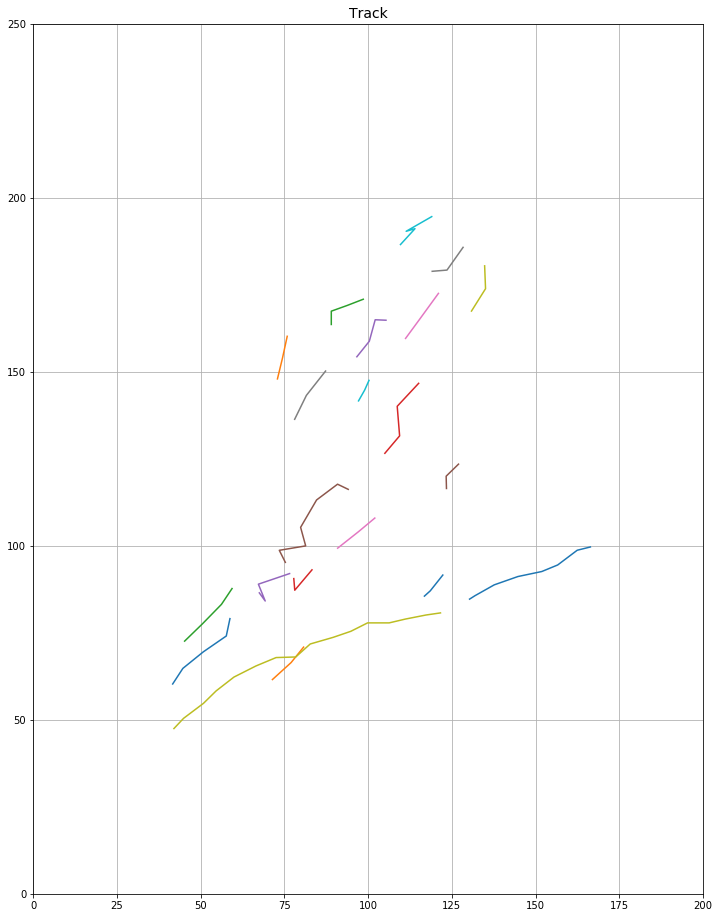

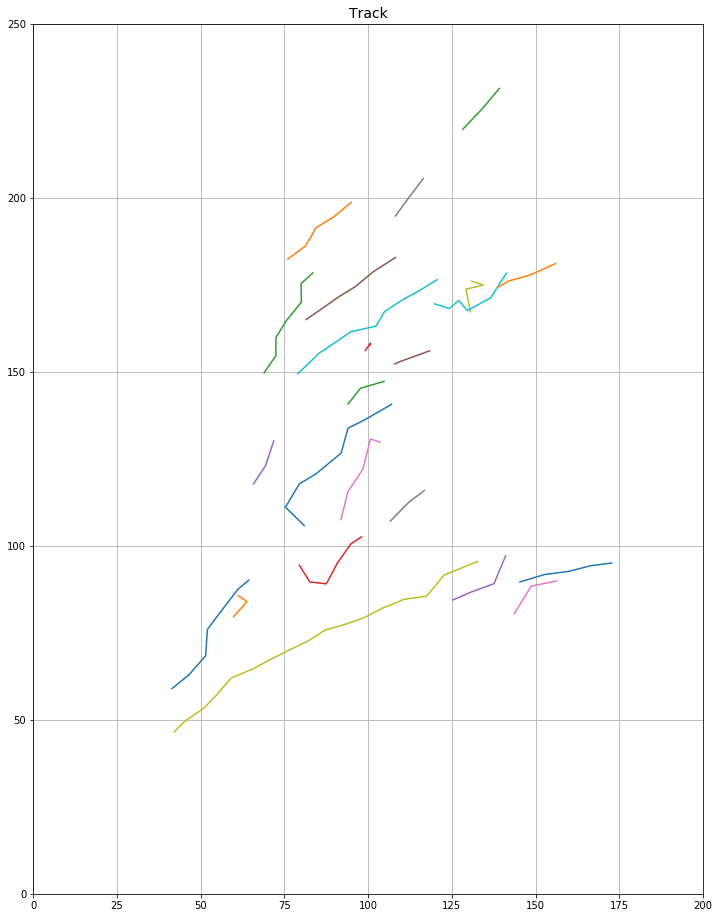

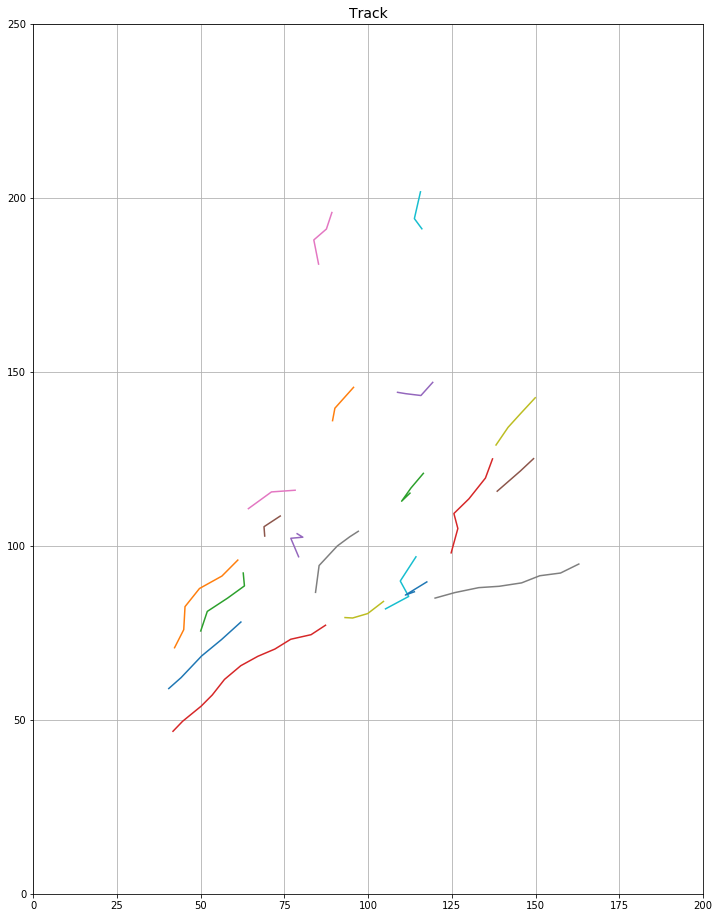

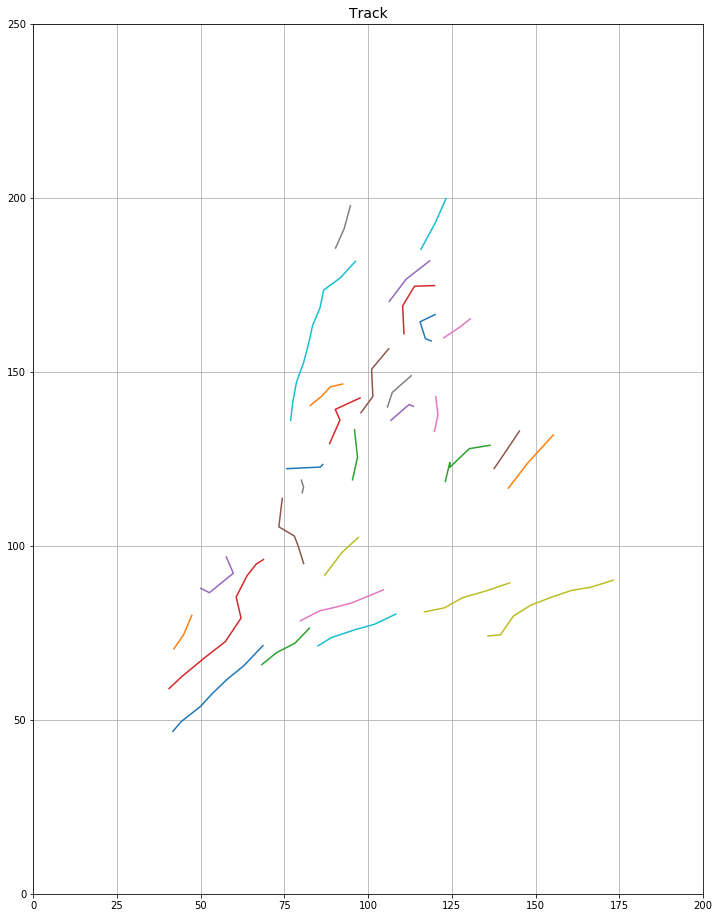

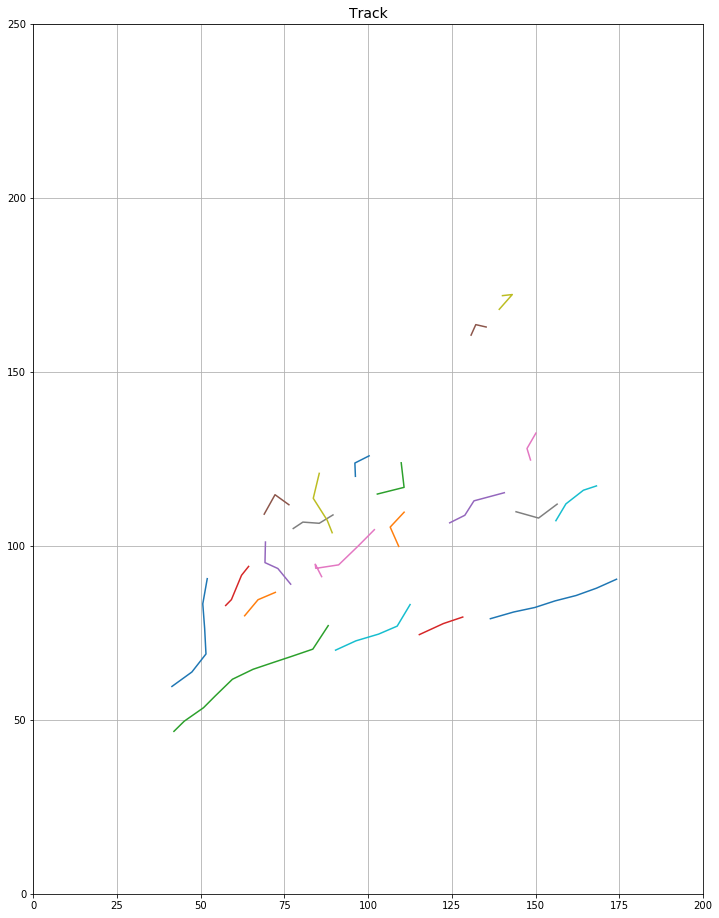

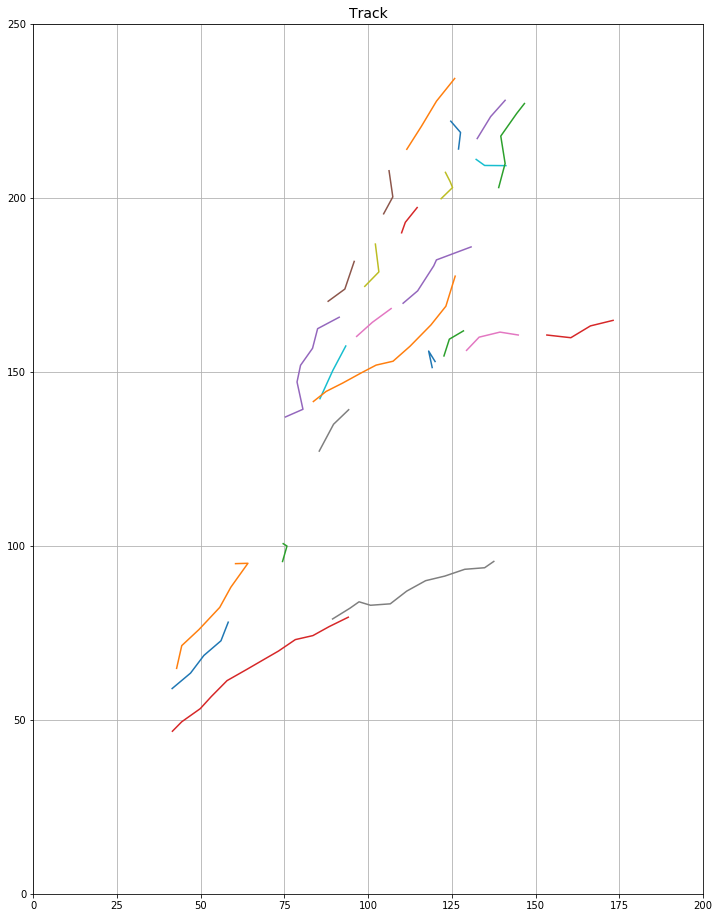

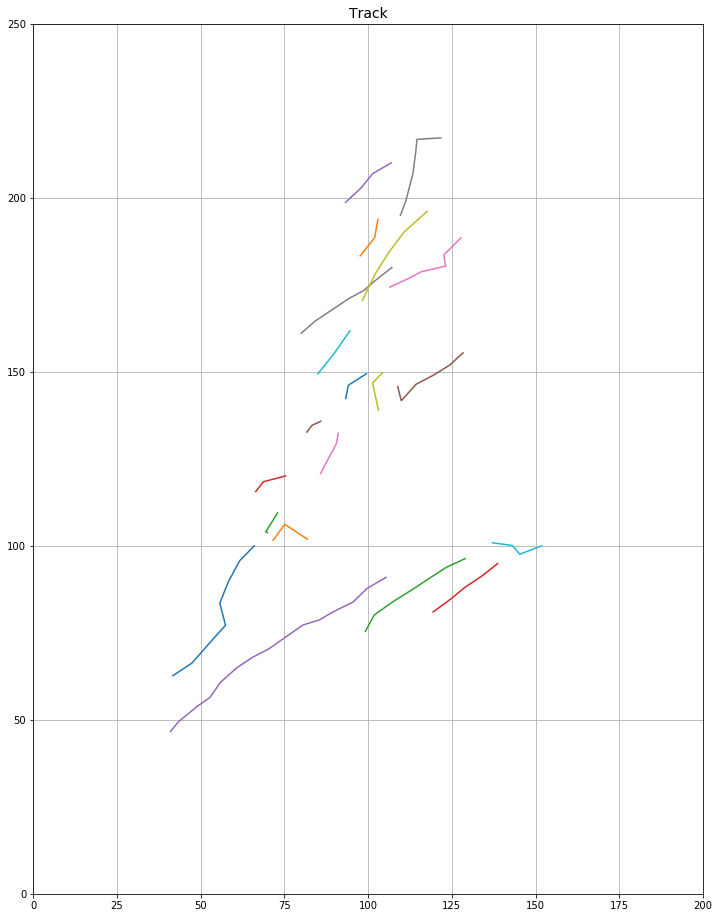

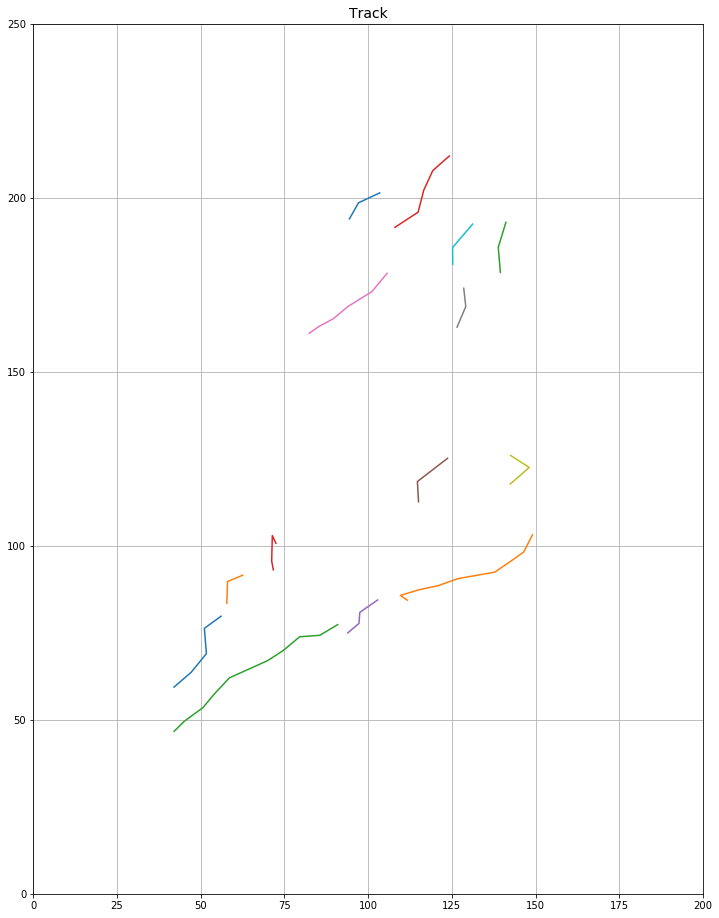

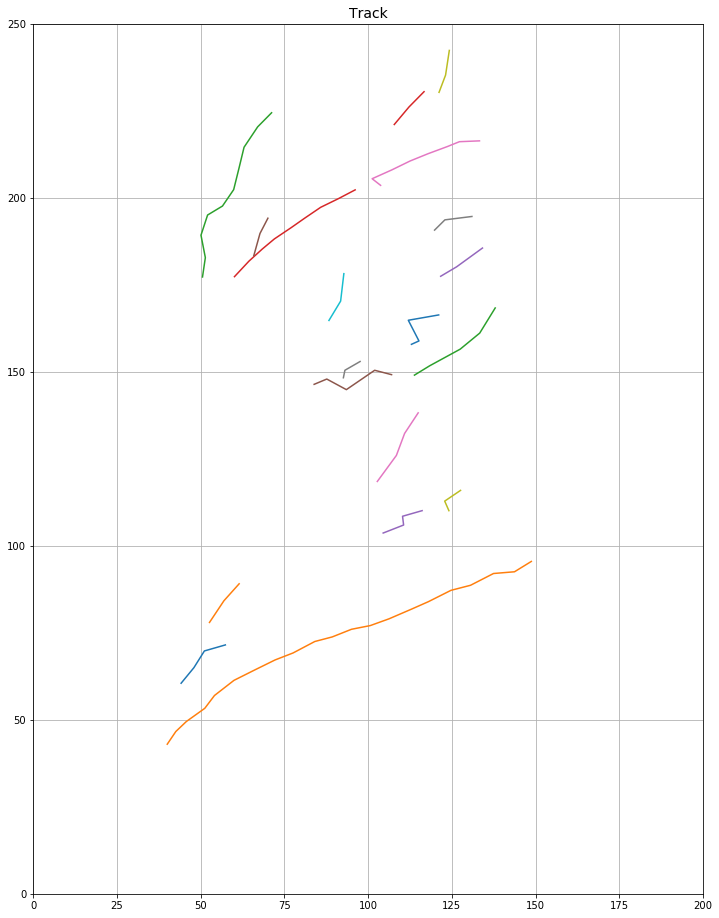

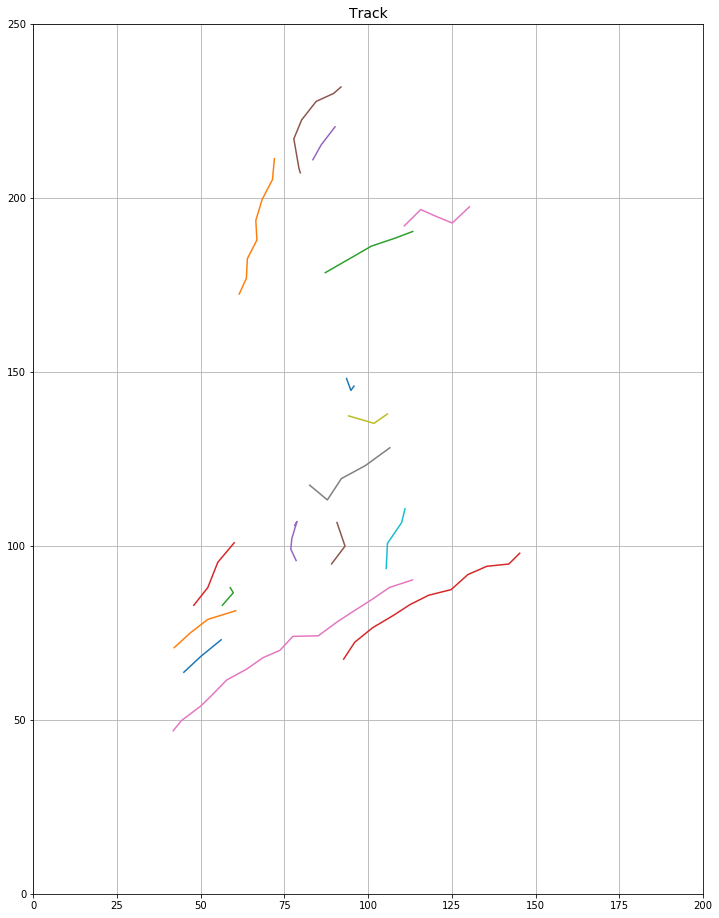

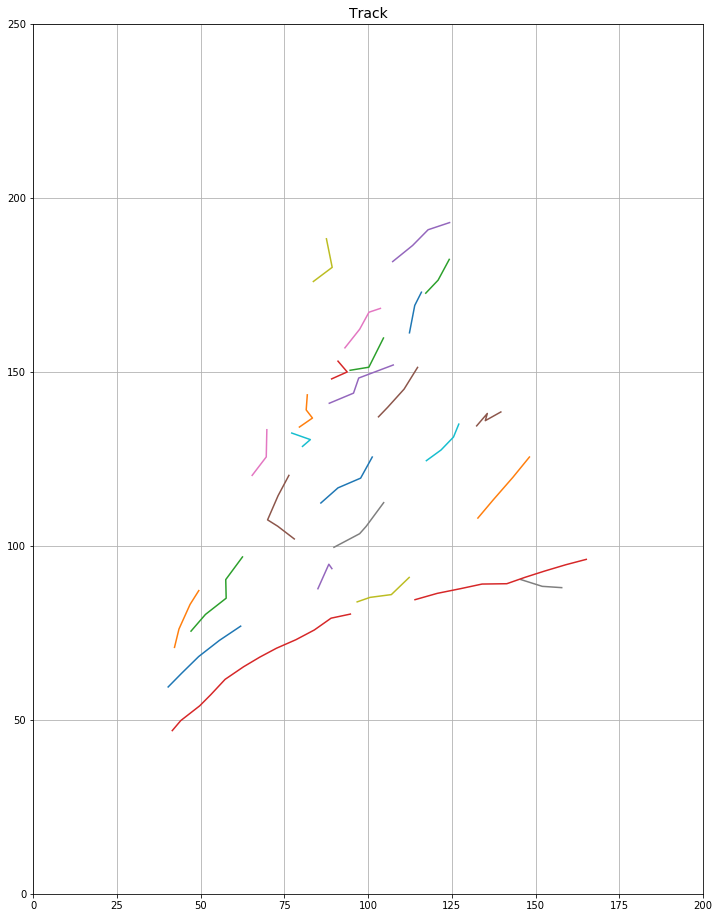

In [194]:
for i in range(0,11):
    inputfile = open('output/'+exp+'/'+str(i)+'/finalUpdrafts.dat', 'r')
    #print(inputfile)
    updrafts  = []
    try:
        while True:
            data = pickle.load(inputfile)
            updrafts.append(data)
    except EOFError:
        print 'Done reading in updrafts...'
        
    inputfile.close()
    time=61
    #print(dir(data))
    xAvg=[]
    yAvg=[]
    
    Nup=np.shape(updrafts)[0]
    #xup=np.zeros(Nup)
    #yup=np.zeros(Nup)
    
    s=0
    xup = {}
    yup = {}
    # for temp4D in updrafts:
    #     temp3D = temp4D.findTime(t)
    #     #print(dir(temp3D.linked2DUpdrafts)
    
    #     if (temp3D != -1):
    #         x = []
    #         y = []
    #         z = []
            
    #         for temp2D in temp3D.linked2DUpdrafts:
    #             for t in range(5):
    #                 print(temp2D.xPos,temp2D.time)
    #                 x.append(temp2D.xPos)
    #                 y.append(temp2D.yPos)
    #                 z.append(temp2D.zPos)
    #         #print(np.mean(x))
    #                 xup["x_{}".format(s)] .append(np.mean(x))
    #                 yup["y_{}".format(s)].append(np.mean(y))
    #     s=s+1
    
    for temp4D in updrafts:
        xup["x_{}".format(s)] = []
        
        yup["y_{}".format(s)] = []
        s=s+1
    s=0
    #print(dir(xup.viewkeys))
    
    xup=np.zeros([Nup+1,time])
    yup=np.zeros([Nup+1,time])
    
    for t in range(time):
        s=0
        for temp4D in updrafts:
            temp3D = temp4D.findTime(t)
            
            #print(temp3D.linked2DUpdrafts)
            if (temp3D != -1):
                x = []
                y = []
                z = []
                for temp2D in temp3D.linked2DUpdrafts:
                    #print(temp2D.savedData)
                    x.append(temp2D.xPos)
                    y.append(temp2D.yPos)
                    z.append(temp2D.zPos)
                #print(np,mean(x),t)
                xup[s,t]=np.mean(x)
                yup[s,t]=np.mean(y)
                #print(s)
            s=s+1
                #xAvg = np.mean(x)
               # yAvg = np.mean(y)
    xup[xup == 0] = np.nan
    #xup = xup[~np.any(np.isnan(xup), axis=0)]
    #xup = xup[~np.any(np.isnan(xup), axis=0)]
    #xup = xup[~np.any(xup == 0, axis=1)]
    #xup = xup[xup[ != 0]
    yup[yup == 0] = np.nan
    #print(xup)
    #print(xup["x_57"])
    #levels_dbz=np.arange(20,60,8)
    
    x=np.arange(0,200,1)
    y=np.arange(0,250,1)
    
    fig = plt.figure(figsize=(12, 16))
    
    ax = fig.add_subplot(1, 1, 1)
    ax.set_title('Track',loc='center',fontsize=14)
    
    # MSLP in contours and min max
    #c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
    #ax.clabel(c1,fmt='%4.1i',fontsize=10)
    print(np.shape(xup),np.shape(yup))
    for t in range(0,Nup-1):
        ax.plot(np.transpose(xup[t,:]), np.transpose(yup[t,:]))
        #print(np.transpose(xup[t,:]), np.transpose(yup[t,:]))
    ax.set_xlim(0,200)
    ax.set_ylim(0,250)
    plt.grid()
    figname="/glade/u/home/fdemartin/plot/track/"+str(exp)+"_"+str(i)
    fig.savefig(figname+'.png',bbox_inches='tight')
    #plt.close()
    
    time1=np.arange(0,time,1)
    
    # data_t=np.transpose(data_max)
    df=pd.DataFrame(np.transpose(xup),index=time1, columns=[str(z) for z in range(1, Nup+2)])
    df.to_csv("/glade/u/home/fdemartin/SPOUT/tracks/xup_"+str(exp)+"_"+str(i)+".csv")
    
    df=pd.DataFrame(np.transpose(yup),index=time1, columns=[str(z) for z in range(1, Nup+2)])
    df.to_csv("/glade/u/home/fdemartin/SPOUT/tracks/yup_"+str(exp)+"_"+str(i)+".csv")
    print("/glade/u/home/fdemartin/SPOUT/tracks/yup_"+str(exp)+"_"+str(i)+".csv")

In [195]:
# #levels_dbz=np.arange(20,60,8)
# x=np.arange(0,200,1)
# y=np.arange(0,250,1)

# fig = plt.figure(figsize=(12, 16))

# ax = fig.add_subplot(1, 1, 1)
# ax.set_title('Track',loc='center',fontsize=14)

# # MSLP in contours and min max
# #c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
# #ax.clabel(c1,fmt='%4.1i',fontsize=10)
# print(np.shape(xup),np.shape(yup))
# for i in range(0,Nup-1):
#     ax.plot(np.transpose(xup[i,:]), np.transpose(yup[i,:]))
# ax.set_xlim(0,200)
# ax.set_ylim(0,250)
# plt.grid()
# figname='/glade/u/home/fdemartin/plot/track.png'
# fig.savefig(figname+'.png',bbox_inches='tight')
# #plt.close()

# time1=np.arange(0,time,1)

# #data_t=np.transpose(data_max)
# df=pd.DataFrame(np.transpose(xup),index=time1, columns=[str(i) for i in range(1, Nup+2)])
# df.to_csv("/glade/u/home/fdemartin/SPOUT/tracks/xup_"+str(exp)+"_"+str(member)+".csv")

# df=pd.DataFrame(np.transpose(yup),index=time1, columns=[str(i) for i in range(1, Nup+2)])
# df.to_csv("/glade/u/home/fdemartin/SPOUT/tracks/yup_"+str(exp)+"_"+str(member)+".csv")